# Sharpness experiment, stage 1: learning-rate brackets for SGD and Adafactor

For its comparison of different optimizers at different batch sizes, the paper did hyperparameter tuning. While the tuned Adam hyperparameters were written to `configs/hparams/lm11m_fwedu_adam.yaml`, the hyperparameters for Adafactor and SGD were not published nor are available in the repo or git history thereof (and SGD wasn't even tuned at all for `B=4096`). Therefore, we must do the hyperparameter tuning ourselves. `walt/scripts/sharpness/bracket.py` re-brackets them for each $B \in \{4096, 256, 16, 1\}$ using the same hyperparameter grid values as in the paper.

To be precise, for SGD the paper optimizes over twenty evenly-spaced values of the peak learning rate in log scale:
$$
    \eta \in \{0.050, 0.064, 0.081, 0.103, 0.132, 0.168, 0.214, 0.273, 0.348, 0.443, 0.564, 0.719, 0.916, 1.168, 1.488, 1.896, 2.416, 3.079, 3.924, 5.000\}
$$

For Adafactor, we optimize over six peak learning rates also evenly spaced in log scale, but scaled by a function of the batch size:
$$
    \eta \in B^{0.3} \cdot 10^{-4} \cdot \{1, 3.5, 12, 41.6, 144, 500\}
$$

and also five possible "half-lives" (which aren't really half-lives according to the paper's implementation; see the discussion below)
$$
    t_2 \in 10^4 \cdot \{100, 316, 1000, 3160, 10000\}
$$

for a total of thirty hyperparameter configurations.

The paper's 30M model experiments run on a TPU v4 chip. Since the paper's code never set a matrix multiplication precision, the TPU's implementation falls back to its default: bfloat16 operands (7 mantissa bits) with FP32 accumulation. In contrast, our GPU's default is to use TF32 operands (10 mantissa bits) with FP32 accumulation. On our GPU, even the "bfloat16" setting for `jax.default_matmul_precision` only uses TF32. On the one hand, this means that our experiments have greater numerical accuracy than those in the paper: on the other hand, throughput is worse.

In order to make this computationally tractable on a single A100 GPU, we make an additional simplification: we run only to 151M tokens instead of all the way to 600M tokens as in the paper, and scale the learning rate schedule accordingly. This will definitely bias the hyperparameter tuning in unpredictable ways, so ideally it would be best to redo this fully with more compute.

We write our found hyperparameters to `walt/runs/sharpness/bracket/best.json`, and for Adam use the paper's values in `configs/hparams/lm11m_fwedu_adam.yaml`.

The bracket is resumable: finished points are read back from disk. This notebook calls it with `--no-train`, which only collects finished runs and refuses to launch anything, so it never touches the GPU.

In [9]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
here = Path.cwd().resolve()                                             # works from the repo root, this folder, or any subfolder
REPO = next((p for p in (here, *here.parents) if (p / 'sharpness' / 'scripts').is_dir()), Path.home() / 'src' / 'batch-size')
assert (REPO / 'sharpness' / 'scripts').is_dir(), f'repo not found from {here}; set REPO by hand'
sys.path.insert(0, str(REPO))
from sharpness.scripts import bracket

results, best = bracket.main(['--no-train'])

sgd_b4096: 20 points -> best lr 0.214 (grid index 6) t2 None loss 8.3708
sgd_b256: 20 points -> best lr 0.348 (grid index 8) t2 None loss 6.9655
sgd_b16: 20 points -> best lr 0.443 (grid index 9) t2 None loss 5.4828
sgd_b1: 20 points -> best lr 0.564 (grid index 10) t2 None loss 4.1818
adafactor_b4096: 30 points -> best lr 0.05044 (grid index 3) t2 1000000 loss 6.4968
adafactor_b256: 30 points -> best lr 0.02196 (grid index 3) t2 1000000 loss 4.9368
adafactor_b16: 30 points -> best lr 0.03315 (grid index 4) t2 1000000 loss 4.0966
adafactor_b1: 30 points -> best lr 0.00416 (grid index 3) t2 1000000 loss 3.9655
wrote /home/ubuntu/src/batch-size/sharpness/runs/bracket/best.json {"sgd": {"4096": {"peak_lr": 0.214, "t2": null}, "256": {"peak_lr": 0.348, "t2": null}, "16": {"peak_lr": 0.443, "t2": null}, "1": {"peak_lr": 0.564, "t2": null}}, "adafactor": {"4096": {"peak_lr": 0.05044304733346604, "t2": 1000000}, "256": {"peak_lr": 0.021956611635260956, "t2": 1000000}, "16": {"peak_lr": 0.0331

## Chosen hyperparameters

Final validation loss after 151M tokens at the chosen point; `points` is the number of bracket runs spent on that (optimizer, $B$).

In [10]:
rows = [dict(optimizer=k.split('_b')[0], B=int(k.split('_b')[1]), peak_lr=v['peak_lr'], grid_index=v['grid_index'], t2=v['t2'], loss=v['loss'], points=len(v['runs']))
        for k, v in results.items()]
table = pd.DataFrame(rows).sort_values(['optimizer', 'B']).set_index(['optimizer', 'B'])
display(table.style.format({'peak_lr': '{:.4g}', 'loss': '{:.4f}', 't2': lambda x: '' if pd.isna(x) else f'{x/1e6:g}M'}))

## Loss against learning rate

**Top:** vanilla SGD, every point of the paper's 20-value grid that has run (crosses at the top of the panel: diverged or exploded runs),
the chosen point circled. **Bottom:** Adafactor on the paper's grid of peak learning rate × second-moment half-life $t_2$, one panel
per batch size, drawn like the paper's Figure 1b: colour is the validation loss above that batch size's best point on a shared scale
clipped at +1 (diverged and exploded runs saturate), and the learning-rate axis is the paper's grid value × $B^{0.3}$ and so differs
per panel. Blank cells have not run yet. The chosen point is the greenest cell of each panel.

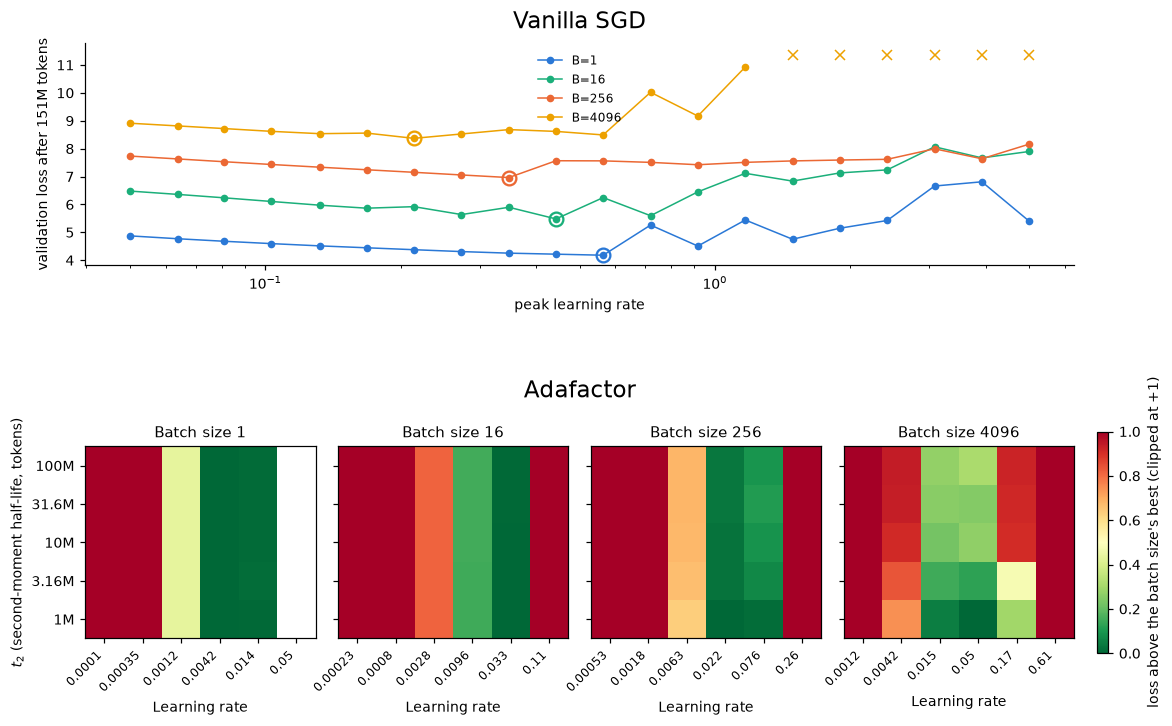

In [11]:
COLOR = {1: '#2a78d6', 16: '#1baf7a', 256: '#eb6834', 4096: '#eda100'}
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})
BS = sorted({int(k.split('_b')[1]) for k in results}); T2S = bracket.T2_GRID; VMAX = 1.0
fig = plt.figure(figsize=(12, 7.2)); gs = fig.add_gridspec(2, 1 + len(BS), width_ratios=[1] * len(BS) + [0.05], height_ratios=[1, 1], wspace=0.12, hspace=0.75)

# left: vanilla SGD, loss against learning rate
ax = fig.add_subplot(gs[0, :-1]); ymax = max(v['loss'] for k, v in results.items() if k.startswith('sgd')) + 3
for B in BS:
    v = results[f'sgd_b{B}']; runs = pd.DataFrame(v['runs']).sort_values('peak_lr'); ok = runs['loss'] < ymax
    ax.plot(runs['peak_lr'][ok], runs['loss'][ok], 'o-', color=COLOR[B], ms=4, lw=1, label=f'B={B}')
    ax.plot(runs['peak_lr'][~ok], np.full((~ok).sum(), ymax), 'x', color=COLOR[B], ms=6)
    ax.plot([v['peak_lr']], [v['loss']], 'o', color=COLOR[B], ms=9, mfc='none', mew=1.5)
ax.set_xscale('log'); ax.set_ylim(top=ymax + 0.4); ax.set_xlabel('peak learning rate'); ax.set_ylabel('validation loss after 151M tokens')
ax.set_title('Vanilla SGD', fontsize=15, pad=10); ax.legend(fontsize=8, frameon=False)

# right: Adafactor on the (peak learning rate x t2) grid, one panel per B, in the style of the paper's Figure 1b
cmap = plt.get_cmap('RdYlGn_r').copy(); cmap.set_bad('white'); bottom = []
for j, B in enumerate(BS):
    v = results[f'adafactor_b{B}']; runs = pd.DataFrame(v['runs'])
    idx = sorted(runs['grid_index'].unique()); grid = np.full((len(T2S), len(idx)), np.nan)
    for _, r in runs.iterrows(): grid[T2S.index(int(r['t2'])), idx.index(int(r['grid_index']))] = r['loss']
    ax = fig.add_subplot(gs[1, j]); bottom.append(ax)
    ax.imshow(np.ma.masked_invalid(grid - v['loss']), cmap=cmap, vmin=0, vmax=VMAX, aspect='equal', origin='lower')   # inf (diverged) saturates
    ax.set_xticks(range(len(idx))); ax.set_xticklabels([f'{bracket.af_lr(i, B):.2g}' for i in idx], rotation=45, ha='right', fontsize=8)
    ax.set_yticks(range(len(T2S))); ax.set_yticklabels([f'{t / 1e6:g}M' for t in T2S] if j == 0 else [])
    ax.set_title(f'Batch size {B}', fontsize=10); ax.set_xlabel('Learning rate')
    if j == 0: ax.set_ylabel('$t_2$ (second-moment half-life, tokens)')
    for sp in ax.spines.values(): sp.set_visible(True)
top = max(a.get_position().y1 for a in bottom); fig.text(np.mean([a.get_position().x0 + a.get_position().x1 for a in bottom]) / 2, top + 0.055, 'Adafactor', fontsize=15, ha='center', va='bottom')
cb = fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, VMAX), cmap=cmap), cax=fig.add_subplot(gs[1, -1])); cb.set_label('loss above the batch size\'s best (clipped at +1)')
(REPO / 'sharpness' / 'runs' / 'figures').mkdir(exist_ok=True); fig.savefig(REPO / 'sharpness' / 'runs' / 'figures' / 'B1_bracket.png', bbox_inches='tight')

# Discussion

## Limitations of Adafactor Experiment

Note that for Adafactor, batch size 1 and 16 have losses that appear completely independent of $t_2$. This is due to a bug in the paper's Adafactor implementation.

While $t_2$ is called a halflife in the paper and the code, it is in fact is not a halflife in the implementation. Given a $t_2$, the upstream code converts it to $b_2 = 2^{-\text{tokens per step}/t_2}$, which matches the halflife-to-EMA conversion it uses for Adam. However, it then calls its Adafactor with `decay_rate=c.b2`. That argument goes to the factored-RMS transform's power-law schedule, which is a schedule
$$
\beta_{2, t} = 1 - (t+1)^{-b_2} = 1 - (t+1)^{-2^{-\text{tokens per step}/t_2}}
$$

For small batch sizes, the exponentiation by something extremely close to $1$ makes virtually no difference.

This is straightforward to fix, but I wanted to perform a follow-up experiment rather than spending = my compute/time reproducing their results correctly. Therefore, I decided to proceed using their "convention" for $t_2$.

## Counterintuitive Result for Vanilla SGD

The optimal peak learning rate for SGD actually *increases* with smaller batch sizes. This is in contrast to the paper's explanation and toy model from Appendix B, which hypothesizes that SGD is more effective at small batch sizes because it is able to run for more iterations and therefore can select a smaller learning rate.

# Sharpness experiment, stage 2: Measuring Sharpness Dynamics as a Function of Training parameters.

For batch sizes $B \in \{1, 16, 256, 4096\}$ and the hyperparameters selected in stage 1 for each of vanilla SGD, Adafactor, and Adam, we will measure how sharpness changes over the course of the training run.

Specifically, for each instant we will attempt to estimate three things:
1. The raw full-batch sharpness $\lambda_\text{max}(H_t)$ where $H$ is the Hessian of the loss over all training sequences in the 600M-token training dataset at time $t$.
2. For Adam, the *preconditioned* full-batch sharpness $\lambda_\text{max}(\hat{P}_t^{-1/2} H_t \hat{P}_t^{-1/2})$, where $\hat{P}_t=\text{diag}(\sqrt{\hat{v}_i}) + \varepsilon \text{Id}$. Here $\hat{v}_t$ is the bias-corrected second-moment accumulator.
3. For Adafactor, the effective preconditioned full-batch sharpness $\lambda_\text{max}(P_t^{-1/2} H_t P_t^{-1/2})$, where $P_t$ is the preconditioning matrix implicit in Adafactor: $$P_t = \text{diag}\left(\frac{\sqrt{\hat{v}_t}}{\rho_b c_b}\right)$$ with the rank-one $\hat{v}$ from the factored statistics, the block clip $c_b$ evaluated at the observed batch gradient, and the parameter-block RMS $\rho_b$.

We will exclude `token_embed_in` and `token_embed_out` weights from all of the above measurements, since those are uniquely dominated by rare events. Our goal here is to see whether we get measurably closer to the EOS regime as batch size increases.

Algorithmically, this goal already presents some interesting problems. For one, computing even the full-batch gradient (much less the full-batch sharpness) is as hard as running the entire training run, precluding exact estimates.

## Estimating raw full-batch sharpness from iid training samples

### Confidence Interval from a Principal Eigenvalue Estimate

Starting with problem (1), we would like to estimate $\lambda_\text{max}(\mathbb E[H_x])$ given samples from a distribution over symmetric matrices $H_x$. We will first reduce this to finding a "good" vector $v$ that lies close to the principal eigenspace of $H = \mathbb E[H_x]$; supposing we have such a vector $v$, we would have
\begin{equation}
    v^\top H v \le \lambda_\text{max}(H) \le \mathbb E[\lambda_\text{max}(H_m)]
\end{equation}
where $H_m$ is the Hessian on $m$ independent samples (the second inequality follows from the convexity of $\lambda_\text{max}$). The first inequality is tight when $v$ is a principal eigenvector, and the second inequality is tight for large enough $m$ (we will deal with how to upper bound $\lambda_\text{max}(H_m)$ later).

Note that both the left and right-hand sides of Equation (1) are expectations of measurable 1D random variables (the first is the expectation of $v^\top H_x v$ for an empirical Hessian of a uniformly random sequence $x$). So, assuming we can compute the random variables they are expectations of, we can draw independent samples and use a 1D mean estimator [LMSV25]. For any $v$ and $m$, this will yield a statistically valid confidence interval (up to the error of the mean estimator).

There is one remaining non-obvious algorithmic detail before we get to how to estimate $v$: how to estimate the Hessian-vector product $H_x v$ can be estimated for a given $v$ and sequence $x$. Letting
$$
    H_x = \nabla^2_\theta L(x, \theta)
$$
as usual, there are two main ways of doing this. The first is to write
$$
    H_x v = \nabla_\theta \left( v^\top \nabla_\theta L(x, \theta)\right)
$$
(the so-called "reverse-over-reverse" form). We can compute the second gradient by keeping track of the operations used to produce the first gradient, and then doing a second layer of backpropogation; this is called double backpropogation.

The second way of doing this is to use the "forward-over-reverse" form
$$
    H_x v = \frac{d}{dt} \nabla_\theta L(x, \theta + tv)|_{t=0}
$$

and we use this one since it is [explicitly recommended](https://docs.pytorch.org/tutorials/intermediate/jacobians_hessians.html#computing-hessian-vector-products) by Pytorch because it uses less memory.

### Estimating a Principal Eigenvector

The remaining issue, then, becomes getting a good estimate for $v$ to make our error bounds as small as possible. We will do this with the Lanczos algorithm, which works for arbitrary symmetric matrices (i.e. either our raw or preconditioned cases).

The Lanczos algorithm works as follows: given a matrix $A$, start with a random unit vector $q_1$. Then at iteration $k$, define the Krylov subspace at time $k$ by
$$
    K_k :=\text{span} \bigcup_{j=0}^{k-1} \{A^j q_1\}
$$

With a Gram-Schmidt procedure per iteration, Lanczos keeps an orthonormal basis $q_1, ..., q_k$ for this subspace at each $k$th iteration. This requires only one application of $A$ to the previous iterate per iteration (feasible with the Hessian-vector product method described above).

We typically do this for a reasonably small value of $k$ so that it is feasible to do a full PCA on the $k \times k$ matrix $T_k=Q_k^\top A Q_k$ (where $Q_k = (q_1,...,q_k)$), which yields
$$
    v_k := \argmax_{v \in K_k \cap \mathbb S^{d-1}} v^\top A v
$$

Finally, given an "early stop parameter" $\varepsilon_*$ we use an additional performance heuristic. Defining the residual $j$ at time $k$ by
$$
r_j = \|A Q_k s_j(T_k) - \lambda_j(T_k) Q_k s_j(T_k)\|_2
$$
(where $s_j$ denotes the $j$'th eigenvector and $\lambda_j$ denotes the $j$'th eigenvalue), we end Lanczos early and output $v_k$ if
$$
\left(\frac{r_1}{\text{SpecGap}(T_k) - r_2}\right)^2 \le \varepsilon_*
$$
on two consecutive steps (after a minimum number of steps have been reached)

### Upper bounding $\lambda_\text{max}(H_m)$

Lanczos by itself can give a lower bound but not an upper bound for $\lambda_\text{max}(H_m)$. We will use the method from [this paper](https://pure.tue.nl/ws/portalfiles/portal/4384612/532451.pdf) to get an upper bound. The idea of this paper is to run Lanczos from a random start for $k$ iterations and consider the characteristic polynomial
$$
    p_k(x) = \text{det}(xI - T_k)
$$

Its largest zero is $L_k = \lambda_\text{max}(T_k)$ and a lower bound is immediate:
$$
    L_k \le \lambda_\text{max}(A)
$$

To get an upper bound, the paper shows that (assuming a uniformly random unit vector for an initial iterate) there is an explicit computable constant $C_{k, \delta}$ (as a function of Lanczos iterates) such that with probability $1-\delta$:
$$
    p_k(\lambda_\text{max}(A)) \le C_{k, \delta}
$$

So, if we start at $x=L_k$ and move $x$ to the right until $p_k(x) = C_{k, \delta}$, we will have found an upper bound $U_k$ for $\lambda_\text{max}(A)$.

In fact, except with probability $\delta$ the above inequality on $p_k(\lambda_\text{max}(A))$ holds simultaneously for all $k$. This means that we can still use an early stopping heuristic like in last section without sacrificing the validity of this upper bound. In this case, the natural early stopping criterion is to stop when
$$
\frac{U_k - L_k}{|L_k|} \le \varepsilon_*
$$

## Tuning for Performance

The runtime of the above experiment is dominated by the Hessian vector products, so we use TF32 on that hot path. We run both Lanczos for at most 40 steps with early-stop threshold $\varepsilon_* = 10^{-3}$ and a minimum step count of $10$. 

We use $\delta=10^{-4}$ confidence on each estimator and use $m=512$ for the sharpness upper bound. Additionally, since the upper bounds are expensive to compute, we will only estimate them at 4 checkpoints for each training trajectory (the lower bounds are computed at 36 instants along the trajectory). Thus, the upper bounds are more of a sanity check to see generally how tight our Lanczos lower bound is.

For the upper bound, we will use 32 $H_m$ samples. For the lower bound (which is much cheaper) we will use 16384 samples.

In [12]:
import json, os, subprocess, sys
from pathlib import Path
import numpy as np, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
here = Path.cwd().resolve()                                             # works from the repo root, this folder, or any subfolder
REPO = next((p for p in (here, *here.parents) if (p / 'sharpness' / 'scripts').is_dir()), Path.home() / 'src' / 'batch-size')
assert (REPO / 'sharpness' / 'scripts').is_dir(), f'repo not found from {here}; set REPO by hand'
RUNS = REPO / 'sharpness' / 'runs'; BEST = json.load(open(RUNS / 'bracket' / 'best.json'))   # the stage-1 picks (Adam: the paper's tuned table)
OPTS = ('sgd', 'adafactor', 'adamw'); BS = (4096, 256, 16, 1)

def run_dir(opt, B):
    """<opt>_b<B>; a run that was stopped after it diverged is kept as it ended under <opt>_b<B>_*_diverged."""
    d = RUNS / f'{opt}_b{B}'
    return d if (d / 'done.json').exists() else next(iter(sorted(RUNS.glob(f'{opt}_b{B}_*_diverged'))), d)

def ensure(opt, B):
    """Train and measure the run unless it is finished or kept as diverged (the command of run_full.sh; an interrupted run resumes), then load it."""
    d = run_dir(opt, B)
    if not ((d / 'done.json').exists() or d.name.endswith('_diverged')):
        hp = [a for k, v in BEST[opt][str(B)].items() if v is not None for a in (f'--{k.replace("_", "-")}', str(v))]
        subprocess.run([sys.executable, '-m', 'sharpness.scripts.train', '--optimizer', opt, '--batch-size', str(B), *hp, '--out', str(d)], cwd=REPO,
                       env={**os.environ, 'XLA_PYTHON_CLIENT_PREALLOCATE': 'true', 'XLA_PYTHON_CLIENT_MEM_FRACTION': '0.9'}, check=True)
    m = json.load(open(d / 'run_manifest.json'))
    lr = np.array(np.memmap(d / 'steps.f32', dtype=np.float32, mode='r', shape=(m['run_params']['K'], 2))[:, 1])     # the learning rate of every update
    load = lambda name: json.load(open(d / name)) if (d / name).exists() else []
    return dict(params=m['run_params'], tokens_per_update=m['tokens_per_update'], lr=lr, eval=load('eval.json'), lower=load('sharpness.json'), upper=load('sharpness_upper.json'))

DATA = {(opt, B): ensure(opt, B) for opt in OPTS for B in BS}

## Plots

We will plot the (preconditioned, if applicable) sharpess at each iteration, as well as the stability threshold determined by the learning rate schedule. The latter is $2/\eta_t$ for SGD and Adafactor, and for Adam it is affected by the momentum EMA coefficient $\beta_1$:
$$
    \frac{2(1 + \beta_1)}{\eta_t (1-\beta_1)}
$$

We expect to see larger batch sizes closer to an EoS regime (oscillating around their stability threshold), while smaller batches may stay farther from the edge of stability.

Secondly, we plot the raw (non-preconditioned) sharpness for Adam and Adafactor. If this decreases with batch size, there may be for some difference in fine-tuning performance depending on batch size used during pretraining.

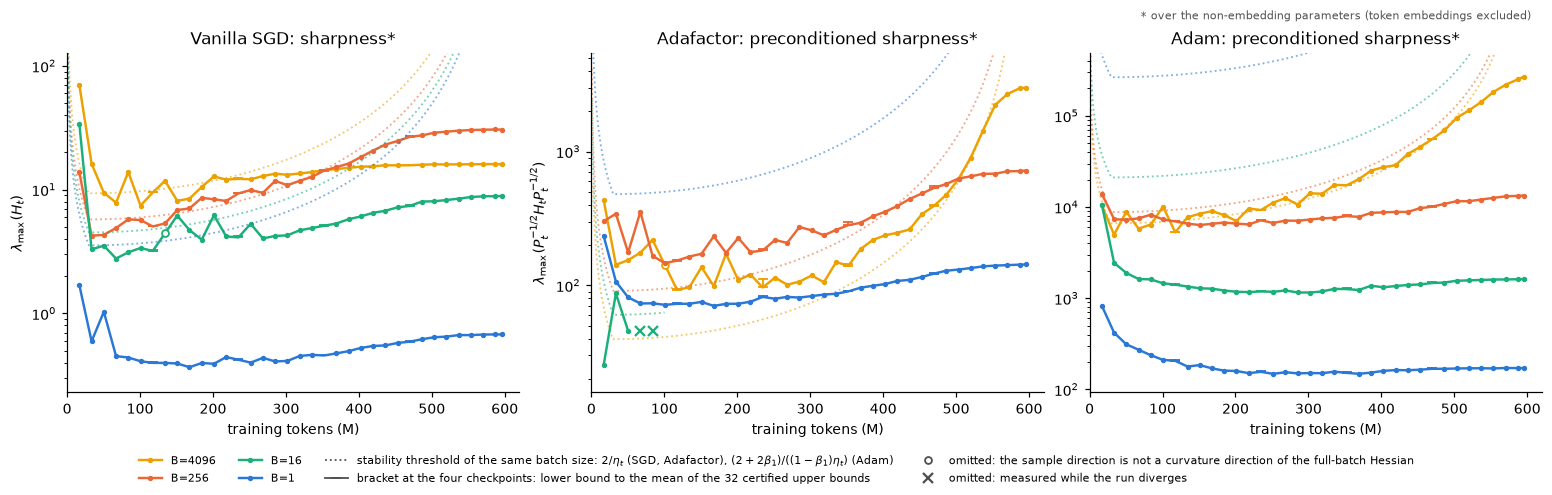

In [13]:
COLOR = {1: '#2a78d6', 16: '#1baf7a', 256: '#eb6834', 4096: '#eda100'}; INK = '#52514e'            # as the stage-1 figure
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})
DUD = 0.05        # an instant is omitted when its fresh-data mean is below this fraction of the sample Ritz value: the direction found is not a curvature direction of the full-batch Hessian
DIVERGE = 1.0     # a run is cut before the first instant from which the validation loss never returns to within this (nats) of the best so far
NAME = {'sgd': 'Vanilla SGD', 'adafactor': 'Adafactor', 'adamw': 'Adam'}
THRESHOLD = {'sgd': lambda lr, p: 2 / lr, 'adafactor': lambda lr, p: 2 / lr, 'adamw': lambda lr, p: (2 + 2 * p['b1']) / ((1 - p['b1']) * lr)}
NOTE = '* over the non-embedding parameters (token embeddings excluded)'

def series(run, kind):
    """One operator's instants up to divergence: tokens (M), lower-bound means, dud mask, brackets at the checkpoints
    [(tokens (M), lower bound, mean of the certified upper bounds)], cut (tokens; inf if none)."""
    loss = np.array([e['eval_loss'] for e in run['eval']]); tail = np.minimum.accumulate(loss[::-1])[::-1]                   # tail[i] = min(loss[i:])
    gone = np.r_[False, tail[1:] > np.minimum.accumulate(loss)[:-1] + DIVERGE]; cut = run['eval'][np.argmax(gone)]['tokens'] if gone.any() else np.inf
    ops = {r['tokens']: r['operators'][kind] for r in run['lower'] if r['tokens'] < cut}
    tok = np.array(list(ops)) / 1e6; val = np.array([o['lower']['mean'] for o in ops.values()]); dud = np.array([o['lower']['mean'] < DUD * o['direction']['L'] for o in ops.values()])
    brackets = [(u['tokens'] / 1e6, ops[u['tokens']]['lower']['mean'], u['operators'][kind]['upper']['mean']) for u in run['upper'] if u['tokens'] in ops]
    return tok, val, dud, brackets, cut

def panel(ax, opt, kind, threshold=None):
    lo, hi = np.inf, 0
    for B in BS:
        run = DATA[(opt, B)]; c = COLOR[B]; tok, val, dud, brackets, cut = series(run, kind); ok = ~dud
        ck = np.isin(tok, [t for t, _, _ in brackets])                                              # checkpoint instants carry a bracket instead of a dot
        ax.plot(tok[ok], val[ok], '-', color=c, lw=1.6); ax.plot(tok[ok & ~ck], val[ok & ~ck], 'o', color=c, ms=2.5)
        if dud.any():                                                                               # omitted instants, on the segment joining their neighbours: open circle (dud), x while the run diverges
            ax.plot(tok[dud], np.exp(np.interp(tok[dud], tok[ok], np.log(val[ok]))), **(dict(marker='x', ls='none', color=c, ms=7, mew=1.5) if cut < np.inf else dict(marker='o', ls='none', mfc='white', mec=c, ms=4.5, mew=1.2)))
        for t, a, b in brackets: ax.plot([t, t], [a, b], '-', color=c, lw=1.2); ax.plot([t, t], [a, b], '_', color=c, ms=7, mew=1.2)
        lo = min(lo, val[ok].min()); hi = max(hi, val[ok].max(), *(b for _, _, b in brackets))
        if threshold is not None:                                                                   # the schedule's threshold, from the learning rate of every update
            lr = run['lr']; k = np.unique(np.linspace(0, len(lr) - 1, 800).astype(int)); t = k * run['tokens_per_update']; k, t = k[t < cut], t[t < cut]
            with np.errstate(divide='ignore'): th = threshold(lr[k].astype(np.float64), run['params'])
            th[~np.isfinite(th)] = np.nan; ax.plot(t / 1e6, th, ':', color=c, lw=1.2, alpha=0.6); hi = max(hi, np.nanmin(th))      # the threshold's peak-lr value stays in view
    ax.set_yscale('log'); ax.set_ylim(lo / 1.6, hi * 1.8); ax.set_xlim(0, 620); ax.set_xlabel('training tokens (M)')

HANDLES = [Line2D([], [], color=COLOR[B], lw=1.6, marker='o', ms=2.5, label=f'B={B}') for B in BS] + [
    Line2D([], [], color=INK, ls=':', lw=1.2, label='stability threshold of the same batch size: $2/\\eta_t$ (SGD, Adafactor), $(2+2\\beta_1)/((1-\\beta_1)\\eta_t)$ (Adam)'),
    Line2D([], [], color=INK, marker='_', ls='-', lw=1.2, ms=7, mew=1.2, label='bracket at the four checkpoints: lower bound to the mean of the 32 certified upper bounds'),
    Line2D([], [], mfc='white', mec=INK, marker='o', ls='none', ms=4.5, mew=1.2, label='omitted: the sample direction is not a curvature direction of the full-batch Hessian'),
    Line2D([], [], color=INK, marker='x', ls='none', ms=7, mew=1.5, label='omitted: measured while the run diverges')]

fig, axs = plt.subplots(1, 3, figsize=(14, 4.4), layout='constrained')
for ax, (opt, kind) in zip(axs, [('sgd', 'raw'), ('adafactor', 'pre'), ('adamw', 'pre')]):
    panel(ax, opt, kind, THRESHOLD[opt]); ax.set_title(NAME[opt] + (': sharpness*' if kind == 'raw' else ': preconditioned sharpness*'), fontsize=11)
axs[0].set_ylabel('$\\lambda_{\\max}(H_t)$'); axs[1].set_ylabel('$\\lambda_{\\max}(P_t^{-1/2} H_t P_t^{-1/2})$')
fig.suptitle(NOTE, x=0.99, ha='right', fontsize=7.5, color=INK)
fig.legend(handles=HANDLES, loc='outside lower center', ncol=4, fontsize=7.5, frameon=False)
plt.show()


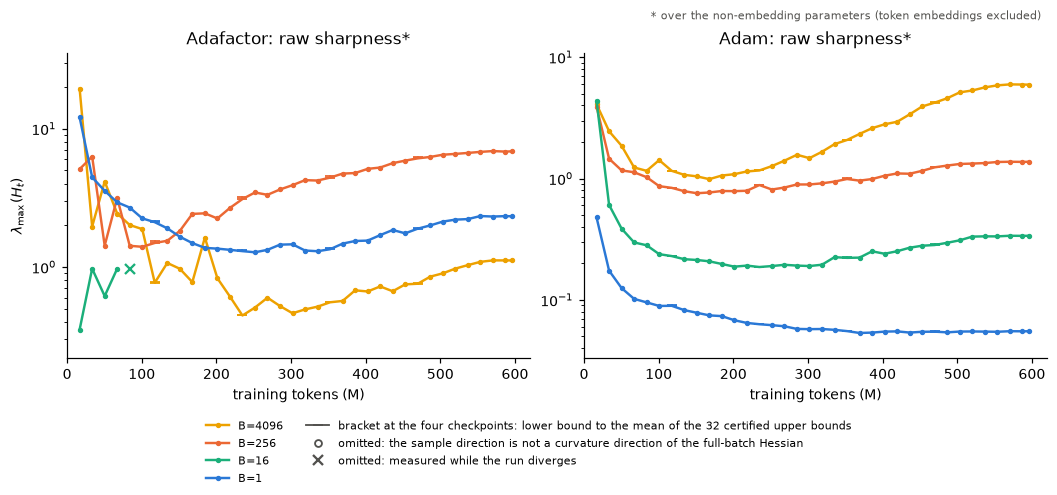

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(9.5, 4.4), layout='constrained')
for ax, opt in zip(axs, ['adafactor', 'adamw']):
    panel(ax, opt, 'raw'); ax.set_title(NAME[opt] + ': raw sharpness*', fontsize=11)
axs[0].set_ylabel('$\\lambda_{\\max}(H_t)$')
fig.suptitle(NOTE, x=0.99, ha='right', fontsize=7.5, color=INK)
fig.legend(handles=HANDLES[:4] + HANDLES[5:], loc='outside lower center', ncol=2, fontsize=7.5, frameon=False)
plt.show()


## Discussion

As expected, the Adafactor results are quite anomalous and difficult to interpret due to the drastically different $\beta_2$ schedule between the batch sizes. The $B=16$ did not even finish successfully due to divergence, which makes me curious about how the paper was able to get reliable results given their bug. This must be an artifact of our hyperparameter tuning methodology compressing the learning schedule to the first 151M tokens (a necessity given computational and time constraints). Most puzzling at all is the fact that Adafactor at $B \in \{256, 4096\}$ seems to be able to stay above its predicted stability threshold for long periods without diverging. This may well be an implementation bug, or something else is going on that I don't understand.

On the bright side, the numerics worked out beautifully with tiny confidence intervals along the points where we computed an upper bound (in most cases you can't even see them on the graph). This is a good sanity check that the lower bound on the rest of the points is close to being tight.

For SGD, $B \in \{16, 256, 4096\}$ all seem to follow EoS dynamics until around halfway through training before breaking off (with $B=16$ breaking off slightly earlier). $B=1$ seems to break off immediately, never even getting close to its EoS threshold. The fact that its run takes place over friendlier geometry explains why the optimal batch size can be increased without a cost to stability.

For Adam, we see that the $B=4096$ case closely follows the EoS dynamics along almost its entire trainining run (until the learning rate gets so small that the stability threshold increases faster than it can keep up). While EoS dynamics have previously been demonstrated for full-batch Adam (Cohen et al 2024), to my knowledge this is the first it has been observed when training transformers with a reasonably small batch size. Then, for Adam as in SGD, we see the stability dynamics consistently get farther away from the EoS boundary as the batch size shrinks.

Altogether, this provides evidence for a major missing component of the Marek et al explanation of the advantage of smaller batch sizes: it seems that smaller batch sizes bias the training dynamics away from the edge of stability and toward smoother regions of the loss function.